Датасет про сорты Бобов

https://www.kaggle.com/datasets/sansuthi/dry-bean-dataset?select=Dry_Bean.csv

Информация об атрибутах:

* Площадь (A): площадь фасолины и количество пикселей в ее границах.
* Периметр (P): окружность фасолины определяется как длина ее границы.
* Длина большой оси (L): расстояние между концами самой длинной линии, которую можно провести от фасолины.
* Длина малой оси (l): самая длинная линия, которую можно провести от фасолины, перпендикулярно главной оси.
* Соотношение сторон (K): определяет соотношение между L и l.
* Эксцентриситет (Ec): эксцентриситет эллипса, имеющего те же моменты, что и исследуемая область.
* Выпуклая область (C): количество пикселей в наименьшем выпуклом многоугольнике, который может вместить площадь семени фасоли.
* Эквивалентный диаметр (Ed): диаметр круга, площадь которого равна площади семени фасоли.
* Экстент (Ex): отношение количества пикселей в ограничительной рамке к площади семени фасоли.
* Плотность (S): также известна как выпуклость. Отношение количества пикселей в выпуклой оболочке к количеству пикселей в бобах.
* Округлость (R): рассчитывается по следующей формуле: (4piA)/(P^2)
* Компактность (CO): измеряет округлость объекта: Ed/L
* ShapeFactor1 (SF1)
* ShapeFactor2 (SF2)
* ShapeFactor3 (SF3)
* ShapeFactor4 (SF4)

Целевая переменная: класс (Seker, Barbunya, Bombay, Cali, Dermosan, Horoz и Sira)

t‑SNE: нелинейное вложение, оптимизирует дивергенцию Кульбака–Лейблера между распределениями близостей точек, хорошо показывает локальные кластеры, но медленно, плохо сохраняет глобальные расстояния, чувствительно к perplexity и random_state.

UMAP: основан на теории многобразий и топологии, строит взвешенный граф соседей и оптимизирует кросс‑энтропию; быстрее t‑SNE, лучше сохраняет глобальную структуру, более устойчив к малым изменениям параметров (n_neighbors, min_dist).

TriMAP: ориентирован на сохранение глобальной структуры через тройки точек (anchor, сосед, далёкий), улучшает глобальное расположение кластеров при сохранении локальной структуры.

PaCMAP: управляет соотношением близких, средних и далёких пар, чтобы одновременно хорошо держать локальные кластеры и общую форму; показывает хорошие результаты на омикс‑данных и эмбеддингах.

PHATE: использует диффузионные процессы и потенциал для визуализации непрерывных траекторий (например, дифференцировка клеток), хорошо показывает как кластеры, так и переходы между ними.



In [2]:
%pip install trimap pacmap phate

  Using cached trimap-1.2.0-py3-none-any.whl.metadata (15 kB)
  Using cached pacmap-0.9.1-py3-none-any.whl.metadata (17 kB)
  Using cached phate-2.0.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached annoy-1.17.3.tar.gz (647 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached torch-2.15.0-cp315-cp315-win_amd64.whl.metadata (36 kB)
INFO: pip is looking at multiple versions of pacmap to determine which version is compatible with other requirements. This could take a while.
  Using cached pacmap-0.9.0-py3-none-any.whl.metadata (17 kB)
  Using cached pacmap-0.8.0-py3-none-any.whl.metadata (14 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

from sklearn.manifold import TSNE
import umap
import trimap
import pacmap
import phate


In [2]:
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
feature_names_iris = iris.feature_names
print(X_iris.shape, np.unique(y_iris))

(150, 4) [0 1 2]


In [3]:
path = "Dry_Bean.csv"  # замените на свой путь
df = pd.read_csv(path)
df.head()


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
df = df[df['Class'].isin(['HOROZ', 'SEKER', 'CALI'])]

In [5]:
class_names = {
    0: 'HOROZ',
    1: 'SEKER',
    2: 'CALI'
}

names = {v: k for k, v in class_names.items()}
df['Class'] = df['Class'].map(names)
df

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,1
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,1
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,1
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,1
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7424,74456,1085.466,447.665972,212.382328,2.107831,0.880298,75096,307.896612,0.788821,0.991478,0.794104,0.687782,0.006012,0.000830,0.473044,0.997097,0
7425,74509,1092.049,456.758154,208.709798,2.188484,0.889499,75260,308.006177,0.797314,0.990021,0.785117,0.674331,0.006130,0.000782,0.454722,0.995153,0
7426,75402,1086.551,448.285753,217.165372,2.064260,0.874827,76439,309.846427,0.784335,0.986434,0.802588,0.691181,0.005945,0.000837,0.477731,0.986160,0
7427,75675,1106.158,452.664524,213.509218,2.120117,0.881774,76468,310.406834,0.612852,0.989630,0.777191,0.685733,0.005982,0.000816,0.470229,0.996941,0


In [6]:
feature_cols = [c for c in df.columns if c != "Class"]
X_own = df[feature_cols].values
y_own = df["Class"].values
print(X_own.shape, len(np.unique(y_own)))

(5585, 16) 3


In [7]:
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)
X_db_scaled = scaler_iris.fit_transform(X_own)

Функции для DR и оценки разделения

In [8]:
def run_tsne(X, random_state=42, perplexity=30, learning_rate=200, n_iter=1000):
    tsne = TSNE(
        perplexity=perplexity, random_state=random_state, learning_rate=learning_rate, n_components=2, max_iter=n_iter
    )
    return tsne.fit_transform(X)

def run_umap(X, random_state=42, n_neighbors=15, min_dist=0.1):
    reducer = umap.UMAP(n_components=2, random_state=random_state, n_neighbors=n_neighbors, min_dist=min_dist)

    return reducer.fit_transform(X)

def run_trimap(X, n_inliers=10, n_outliers=5):
    reducer = trimap.TRIMAP(n_inliers=n_inliers, n_outliers=n_outliers, n_dims=2)

    return reducer.fit_transform(X)

def run_pacmap(X, random_state=42, n_neighbors=10):
    reducer = pacmap.PaCMAP(n_components=2, random_state=random_state, n_neighbors=n_neighbors)

    return reducer.fit_transform(X)

def run_phate(X, random_state=42, knn=15):
    phate_op = phate.PHATE(n_components=2, random_state=random_state, knn=knn)

    return phate_op.fit_transform(X)

Функция оценки качества разделения

In [9]:
def separation_score(X_2d, y):
    D = pairwise_distances(X_2d)
    same = D[y[:, None] == y[None, :]]
    diff = D[y[:, None] != y[None, :]]
    return same.mean(), diff.mean(), diff.mean() / same.mean()

In [10]:
# Отрисовка

def plot_embedding(X_2d, y, title):
    plt.figure(figsize=(6, 5))
    sns.scatterplot(
        x=X_2d[:, 0],
        y=X_2d[:, 1],
        hue=y,
        palette="tab10",
        s=30,
        legend="full"
    )
    plt.title(title)
    plt.xticks([])
    plt.yticks([])
    plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.05 seconds.
    Calculating affinities...


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    Calculated affinities in 4.22 seconds.
  Calculated graph and diffusion operator in 4.30 seconds.
  Calculating optimal t...
    Automatically selected t = 22
  Calculated optimal t in 0.07 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.05 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.50 seconds.
Calculated PHATE in 4.95 seconds.


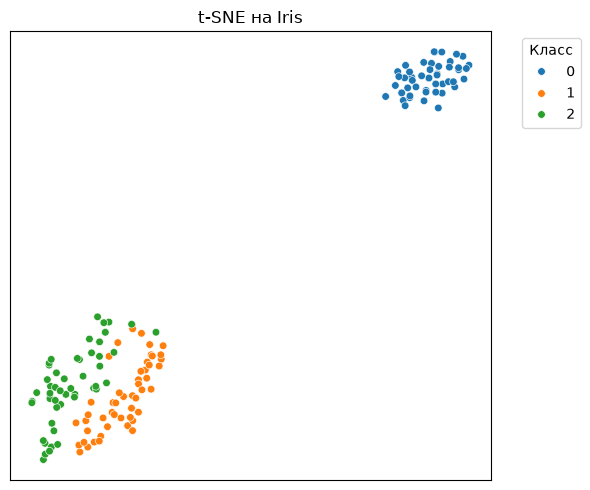

t-SNE: внутрикласс.=3.580, межкласс.=28.091, ratio=7.846


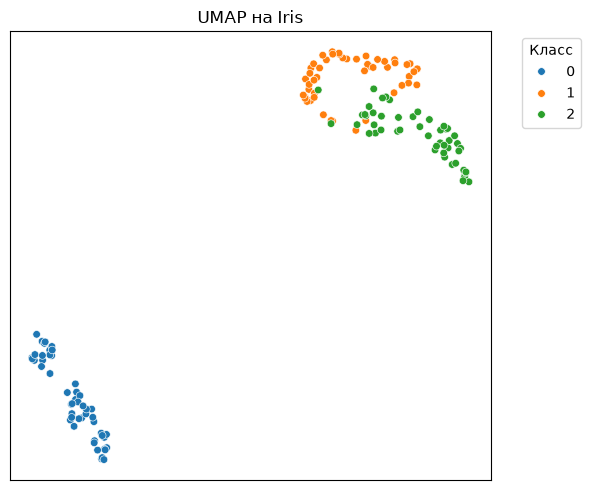

UMAP: внутрикласс.=1.882, межкласс.=11.215, ratio=5.960


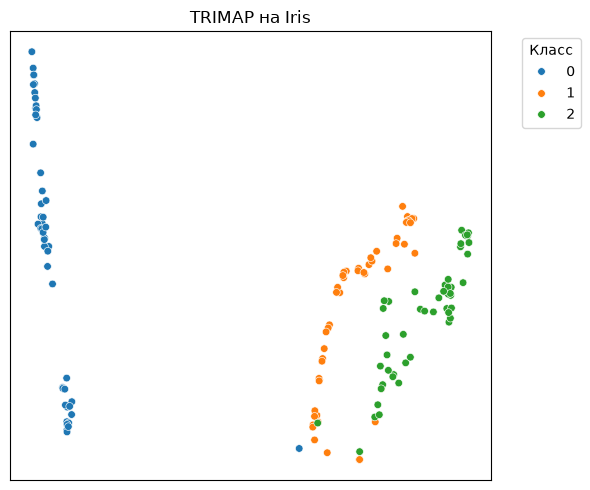

TRIMAP: внутрикласс.=11.078, межкласс.=60.993, ratio=5.506


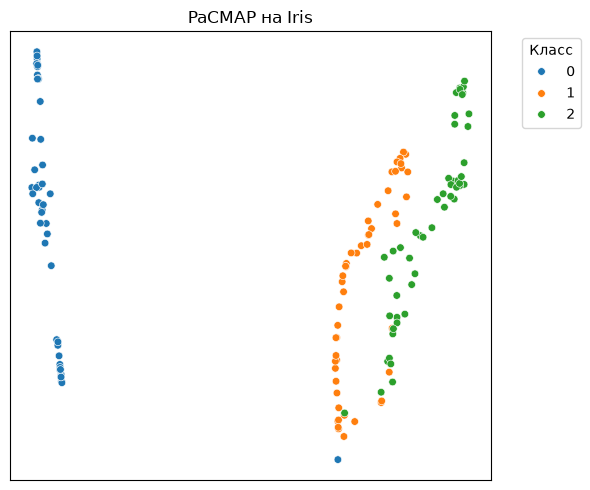

PaCMAP: внутрикласс.=3.471, межкласс.=17.697, ratio=5.099


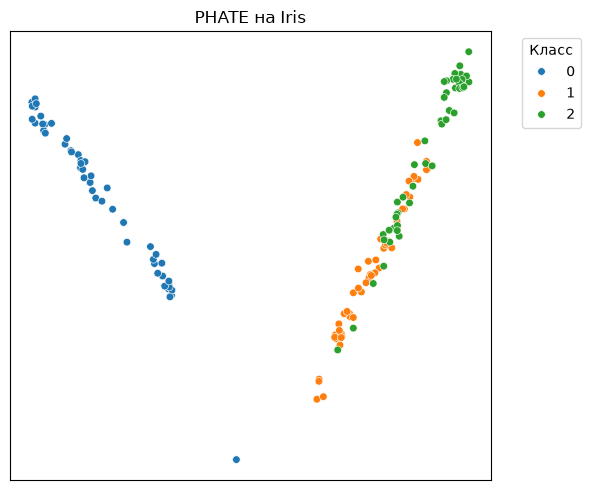

PHATE: внутрикласс.=0.026, межкласс.=0.121, ratio=4.610


In [11]:
X_list = []
names = []

X_tsne_iris = run_tsne(X_iris_scaled, random_state=42)
X_list.append(X_tsne_iris); names.append("t-SNE")

X_umap_iris = run_umap(X_iris_scaled, random_state=42)
X_list.append(X_umap_iris); names.append("UMAP")

X_trimap_iris = run_trimap(X_iris_scaled)
X_list.append(X_trimap_iris); names.append("TRIMAP")

X_pacmap_iris = run_pacmap(X_iris_scaled, random_state=42)
X_list.append(X_pacmap_iris); names.append("PaCMAP")

X_phate_iris = run_phate(X_iris_scaled, random_state=42)
X_list.append(X_phate_iris); names.append("PHATE")

for X_emb, name in zip(X_list, names):
    plot_embedding(X_emb, y_iris, f"{name} на Iris")
    same, diff, ratio = separation_score(X_emb, y_iris)
    print(
        f"{name}: внутрикласс.={same:.3f}, межкласс.={diff:.3f}, ratio={ratio:.3f}"
    )


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Calculating PHATE...
  Running PHATE on 5585 observations and 16 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.51 seconds.
    Calculating affinities...


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\graphtools\graphs.py:810: RuntimeWarning: Detected zero distance between 53 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    Calculated affinities in 0.32 seconds.
  Calculated graph and diffusion operator in 0.86 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 1.50 seconds.
    Calculating KMeans...
    Calculated KMeans in 8.00 seconds.
  Calculated landmark operator in 9.51 seconds.
  Calculating optimal t...
    Automatically selected t = 23
  Calculated optimal t in 8.76 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 2.19 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 6.75 seconds.
Calculated PHATE in 29.64 seconds.


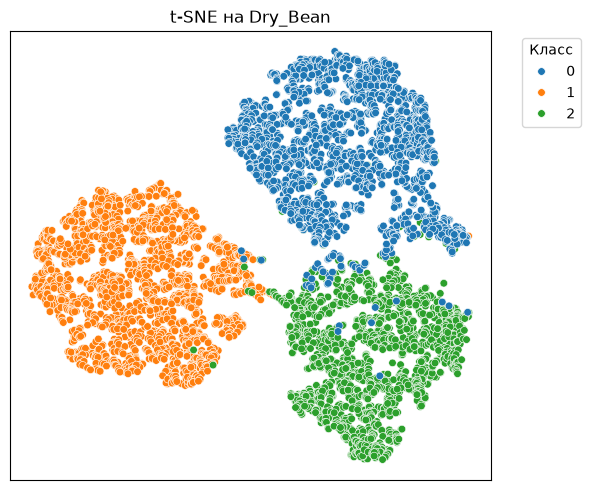

t-SNE: внутрикласс.=33.612, межкласс.=84.703, ratio=2.520


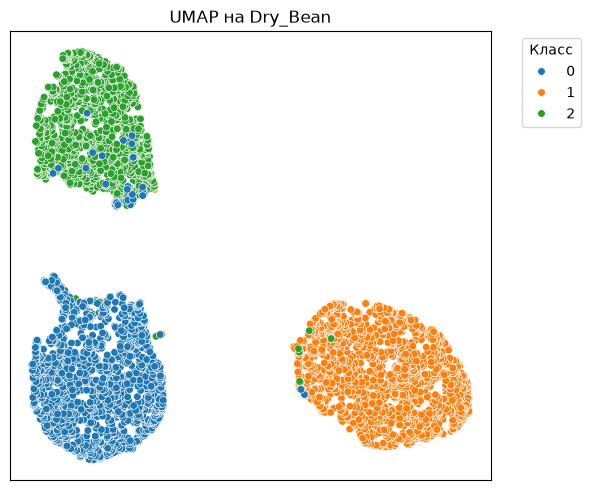

UMAP: внутрикласс.=2.846, межкласс.=11.678, ratio=4.103


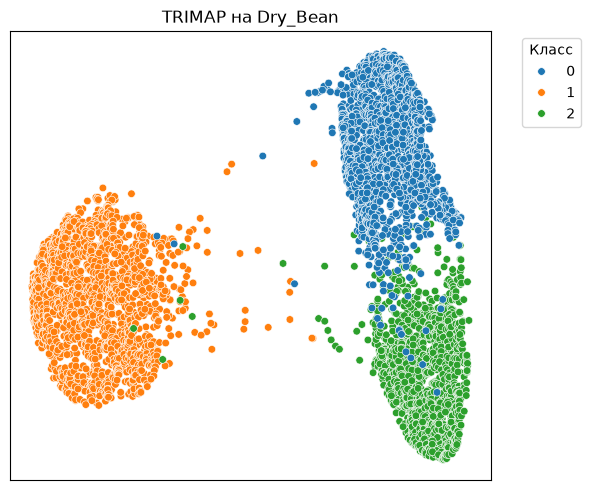

TRIMAP: внутрикласс.=17.756, межкласс.=90.871, ratio=5.118


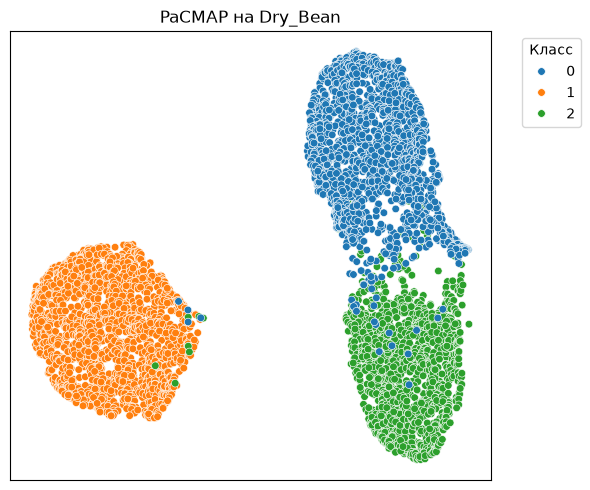

PaCMAP: внутрикласс.=5.085, межкласс.=19.781, ratio=3.890


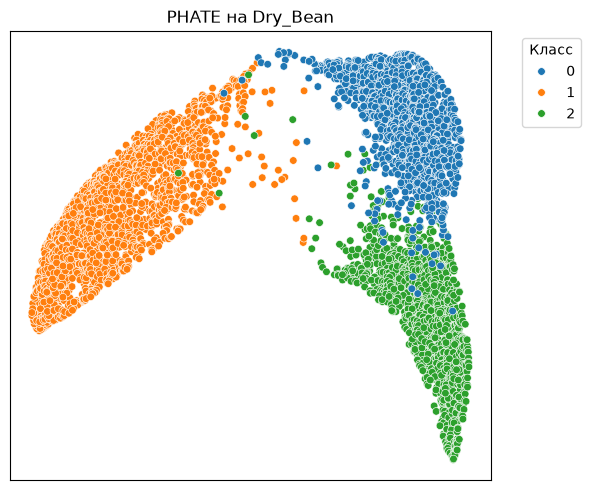

PHATE: внутрикласс.=0.009, межкласс.=0.034, ratio=3.959


In [12]:
X_list = []
names = []

X_tsne_db = run_tsne(X_db_scaled, random_state=42)
X_list.append(X_tsne_db); names.append("t-SNE")

X_umap_db = run_umap(X_db_scaled, random_state=42)
X_list.append(X_umap_db); names.append("UMAP")

X_trimap_db = run_trimap(X_db_scaled)
X_list.append(X_trimap_db); names.append("TRIMAP")

X_pacmap_db = run_pacmap(X_db_scaled, random_state=42)
X_list.append(X_pacmap_db); names.append("PaCMAP")

X_phate_db= run_phate(X_db_scaled, random_state=42)
X_list.append(X_phate_db); names.append("PHATE")

for X_emb, name in zip(X_list, names):
    plot_embedding(X_emb, y_own, f"{name} на Dry_Bean")
    same, diff, ratio = separation_score(X_emb, y_own)
    print(
        f"{name}: внутрикласс.={same:.3f}, межкласс.={diff:.3f}, ratio={ratio:.3f}"
    )

Сравнение устойчивости

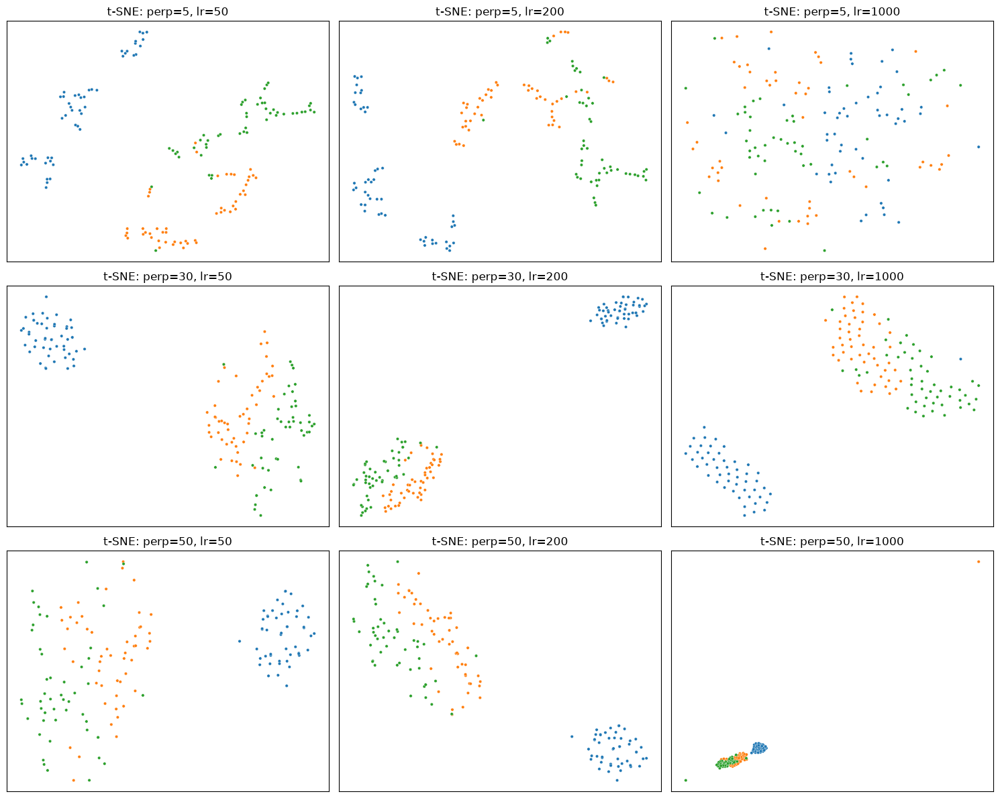

In [13]:
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        X_emb = run_tsne(X_iris_scaled, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

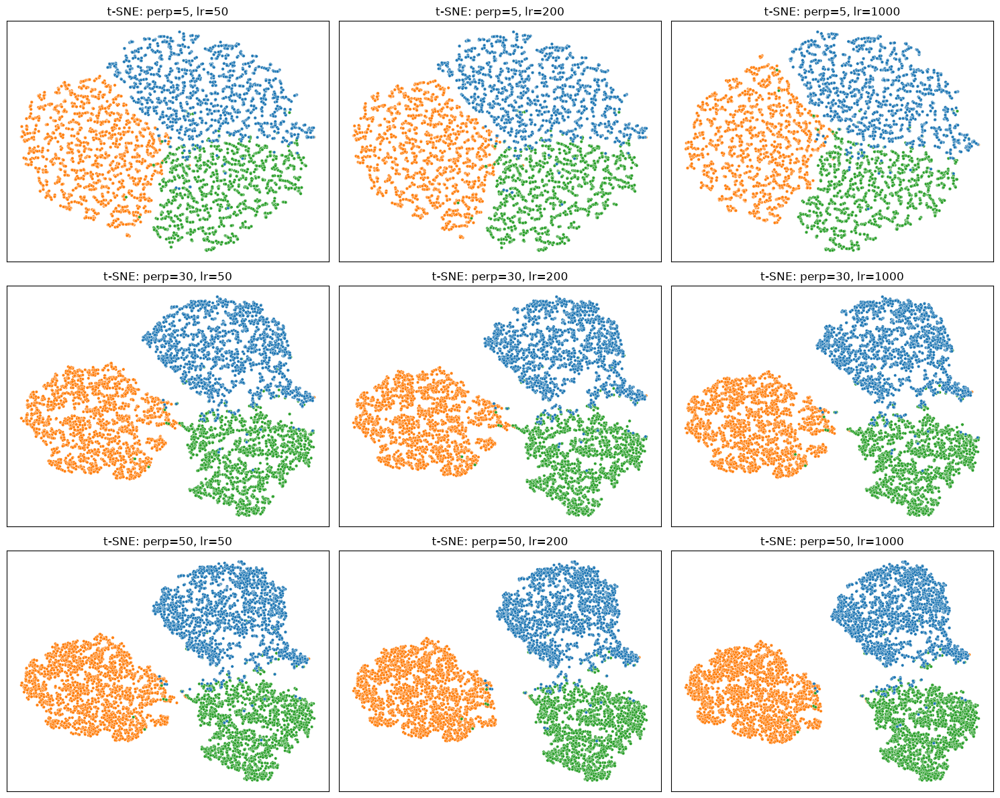

In [14]:
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        X_emb = run_tsne(X_db_scaled, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

Нужно описать, как меняется форма и расположение кластеров при разных perplexity и learning_rate и что визуализация t‑SNE может сильно меняться.

**Iris**

t-SNE показывает нестабильность при изменинии параметеров. При малом значении perplexity=5 и высоком learning_rate=1000 полностью разрушется структура. При высоких perplexity=50 и learning_rate=1000 обратная картина - все значения собираются в одной кучке. Более оптимальный результат показало сочетание perplexity=30 и learning_rate=200.

**Dry Bean**

t-SNE показывает хорошую устойчивость к изменению параметров. При увеличении perplexity расстояние между классами увеличивается и они становятся плотнее. С ростом learning_rate картина почти не изменяется. 

UMAP

c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest

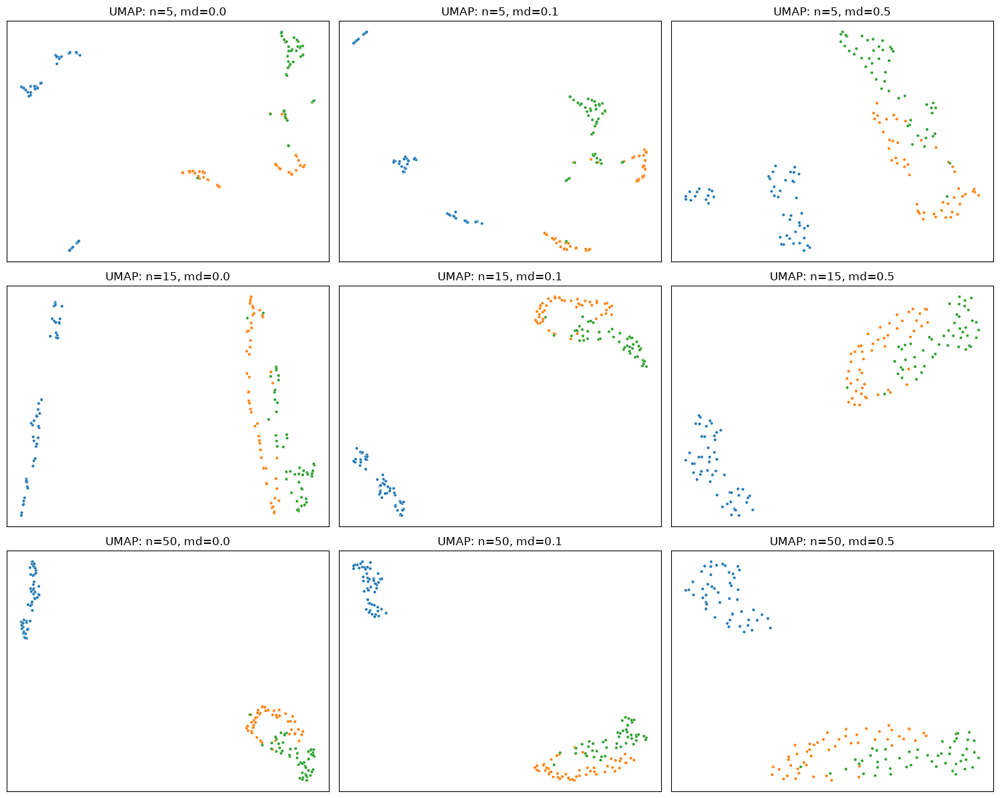

In [15]:
n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        X_emb = run_umap(X_iris_scaled, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"UMAP: n={n}, md={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest

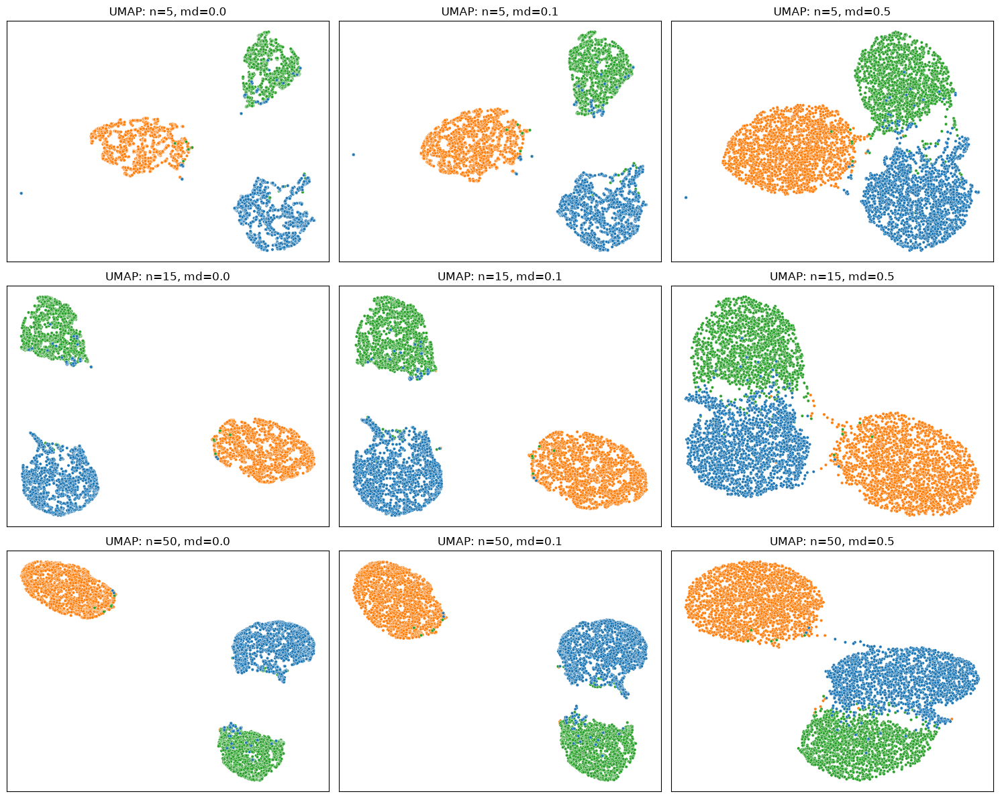

In [17]:
n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))

for i, n in enumerate(n_neighbors):
    for j, m in enumerate(md):
        X_emb = run_umap(X_db_scaled, random_state=42, n_neighbors=n, min_dist=m)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"UMAP: n={n}, md={m}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

**Iris**

UMAP выглядит стабильнее в том плане, что нет такого смешивания классов, как это было при t-SNE. При этом картина все равно сильно меняется. При увеличении n кластеры становятся более плотными. При росте md кластеры меняют форму (от линий в облака).

**Dry Bean**

UMAP справляется хорошо, стабильно видно три плотных кластера. При увеличении md кластеры становятся больше, границы между ними смызываются. При увеличении n_neighbor кластеры приобретают более гладкие и собранные формы.

Обычно структура UMAP меняется плавнее, кластеры остаются узнаваемыми при разумном диапазоне параметров.

*Задача* Аналогично нужно сделать по одной строке графиков для TriMAP, PaCMAP, PHATE с варьированием ключевого параметра (количество соседей или похожий гиперпараметр) и показать, насколько устойчив рисунок.

TRIMAP

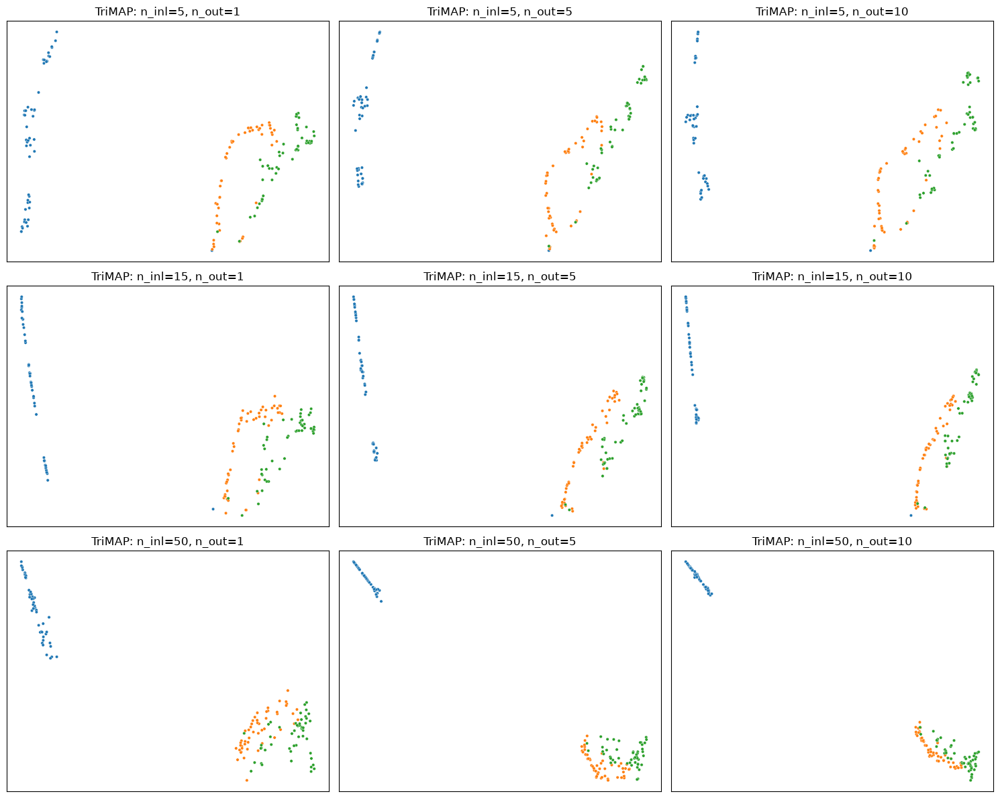

In [24]:
n_inliers = [5, 15, 50]
n_outliers = [1, 5, 10]

fig, axes = plt.subplots(len(n_inliers), len(n_outliers), figsize=(5*len(n_outliers), 4*len(n_inliers)))

for i, n_inl in enumerate(n_inliers):
    for j, n_out in enumerate(n_outliers):
        X_emb = run_trimap(X_iris_scaled, n_inliers=n_inl, n_outliers=n_out)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"TriMAP: n_inl={n_inl}, n_out={n_out}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

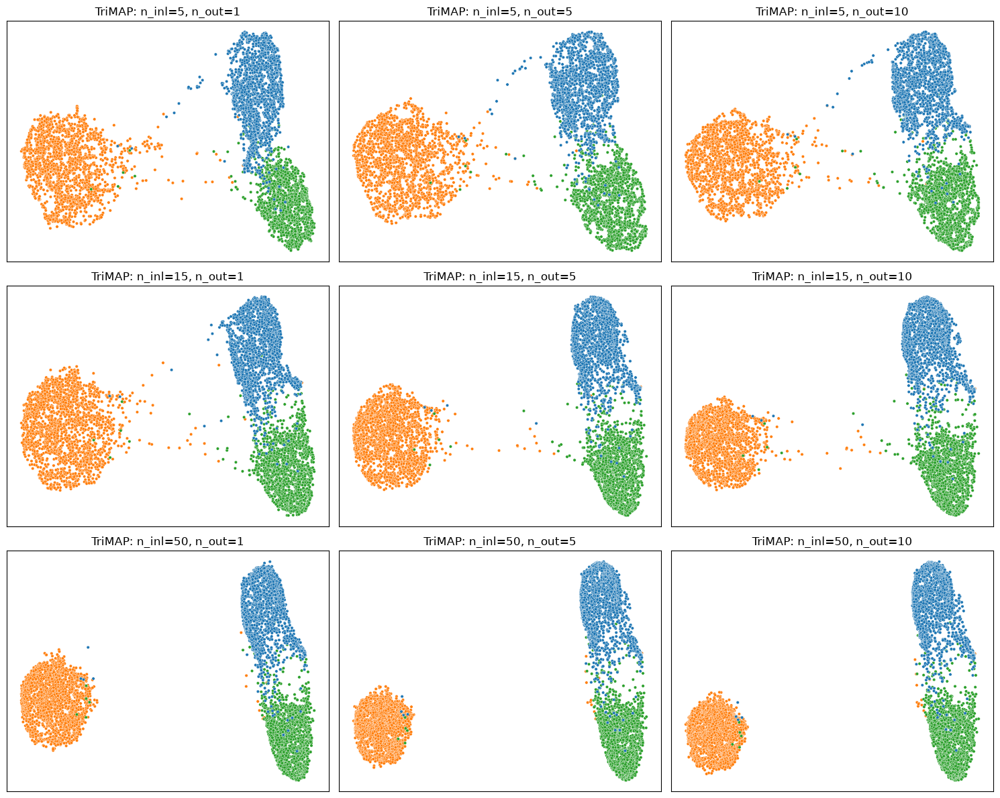

In [25]:
n_inliers = [5, 15, 50]
n_outliers = [1, 5, 10]

fig, axes = plt.subplots(len(n_inliers), len(n_outliers), figsize=(5*len(n_outliers), 4*len(n_inliers)))

for i, n_inl in enumerate(n_inliers):
    for j, n_out in enumerate(n_outliers):
        X_emb = run_trimap(X_db_scaled, n_inliers=n_inl, n_outliers=n_out)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"TriMAP: n_inl={n_inl}, n_out={n_out}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

PaCMAP

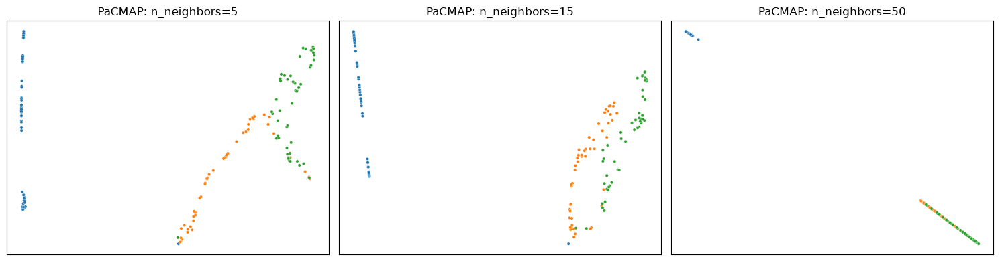

In [26]:
n_neighbors = [5, 15, 50]

fig, axes = plt.subplots(1, len(n_neighbors), figsize=(5*len(n_neighbors), 4))

for i, n_neigh in enumerate(n_neighbors):
    X_emb = run_pacmap(X_iris_scaled, random_state=42, n_neighbors=n_neigh)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PaCMAP: n_neighbors={n_neigh}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

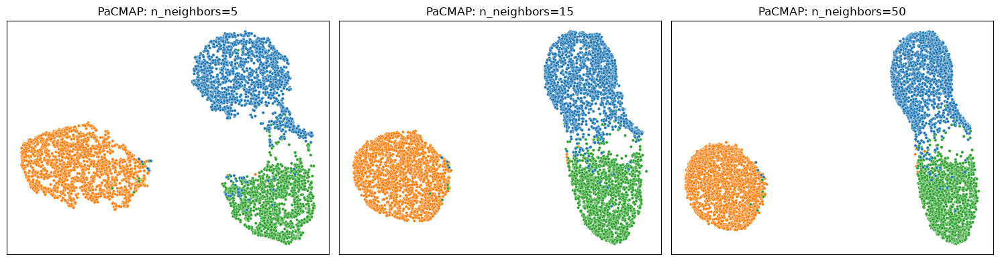

In [27]:
n_neighbors = [5, 15, 50]

fig, axes = plt.subplots(1, len(n_neighbors), figsize=(5*len(n_neighbors), 4))

for i, n_neigh in enumerate(n_neighbors):
    X_emb = run_pacmap(X_db_scaled, random_state=42, n_neighbors=n_neigh)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PaCMAP: n_neighbors={n_neigh}")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

PHATE

Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
  Calculating optimal t...
    Automatically selected t = 21
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.10 seconds.
Calculated PHATE in 0.13 seconds.
Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
  Calculating optimal t...
    Automatically selected t = 22
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by -1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.11 seconds.
Calculated PHATE in 0.14 seconds.
Calculating PHATE...
  Running PHATE on 150 observations and 4 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculating affinities...
  Calculated graph and diffusion operator in 0.02 seconds.
  Calculating optimal t...
    Automatically selected t = 4
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -2.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.11 seconds.
Calculated PHATE in 0.14 seconds.


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\graphtools\graphs.py:803: RuntimeWarning: Detected zero distance between samples 101 and 142. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


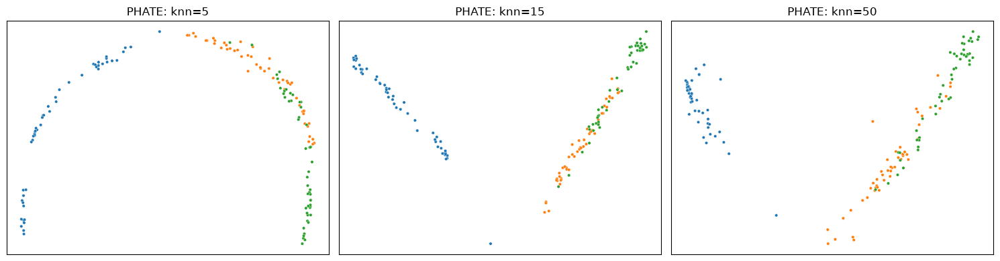

In [28]:
knn = [5, 15, 50]

fig, axes = plt.subplots(1, len(knn), figsize=(5*len(knn), 4))

for i, k in enumerate(knn):
    X_emb = run_phate(X_iris_scaled, random_state=42, knn=k)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PHATE: knn={k}")
    ax.set_xticks([]); ax.set_yticks([])
    
plt.tight_layout()
plt.show()

Calculating PHATE...
  Running PHATE on 5585 observations and 16 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.14 seconds.
    Calculating affinities...
    Calculated affinities in 0.11 seconds.
  Calculated graph and diffusion operator in 0.26 seconds.
  Calculating landmark operator...
    Calculating SVD...


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\graphtools\graphs.py:810: RuntimeWarning: Detected zero distance between 53 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    Calculated SVD in 0.41 seconds.
    Calculating KMeans...
    Calculated KMeans in 2.70 seconds.
  Calculated landmark operator in 3.12 seconds.
  Calculating optimal t...
    Automatically selected t = 37
  Calculated optimal t in 2.48 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.69 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -2.3% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 2.66 seconds.
Calculated PHATE in 9.59 seconds.
Calculating PHATE...
  Running PHATE on 5585 observations and 16 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.17 seconds.
    Calculating affinities...
    Calculated affinities in 0.13 seconds.
  Calculated graph and diffusion operator in 0.31 seconds.
  Calculating landmark operator...
    Calculating SVD...


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\graphtools\graphs.py:810: RuntimeWarning: Detected zero distance between 53 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    Calculated SVD in 0.54 seconds.
    Calculating KMeans...
    Calculated KMeans in 2.60 seconds.
  Calculated landmark operator in 3.14 seconds.
  Calculating optimal t...
    Automatically selected t = 23
  Calculated optimal t in 2.12 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.62 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 2.63 seconds.
Calculated PHATE in 9.28 seconds.
Calculating PHATE...
  Running PHATE on 5585 observations and 16 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.31 seconds.
    Calculating affinities...
    Calculated affinities in 0.17 seconds.
  Calculated graph and diffusion operator in 0.50 seconds.
  Calculating landmark operator...
    Calculating SVD...


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\graphtools\graphs.py:810: RuntimeWarning: Detected zero distance between 53 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    Calculated SVD in 0.83 seconds.
    Calculating KMeans...
    Calculated KMeans in 2.48 seconds.
  Calculated landmark operator in 3.31 seconds.
  Calculating optimal t...
    Automatically selected t = 23
  Calculated optimal t in 2.23 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.68 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.1% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 2.64 seconds.
Calculated PHATE in 9.81 seconds.


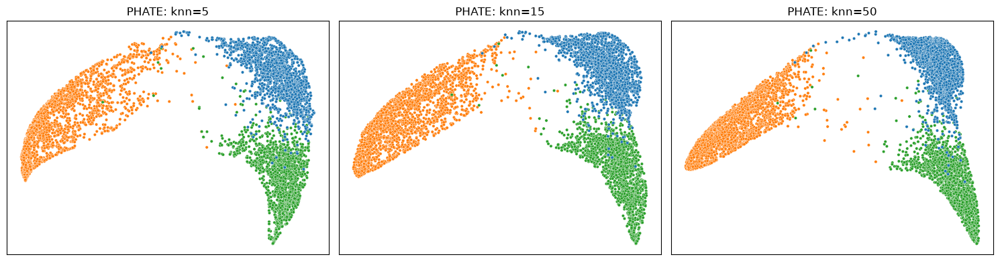

In [29]:
knn = [5, 15, 50]

fig, axes = plt.subplots(1, len(knn), figsize=(5*len(knn), 4))

for i, k in enumerate(knn):
    X_emb = run_phate(X_db_scaled, random_state=42, knn=k)
    ax = axes[i]
    sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"PHATE: knn={k}")
    ax.set_xticks([]); ax.set_yticks([])
    
plt.tight_layout()
plt.show()

| Метод  | Скорость на больших данных                   | Локальное разделение              | Глобальная структура                            | Чувствительность к параметрам                         | Комментарий                                        |
| ------ | -------------------------------------------- | --------------------------------- | ----------------------------------------------- | ----------------------------------------------------- | -------------------------------------------------- |
| t‑SNE  | Низкая l                    | Отличное                   | Слабая                                   | Высокая (perplexity, lr, random_state) aicompetence+2 | Хорошо для локальных кластеров, тяжёлый тюнинг     |
| UMAP   | Высокая l                   | Очень хорошее   | Лучшая, чем у t‑SNE           | Ниже, чем у t‑SNE aicompetence+2                      | Хороший баланс локал/глобал, удобен в практике     |
| TriMAP | Средняя                              | Хорошее                   | Сильный упор на глобальную структуру    | Умеренная                                     | Лучше показывает относительное положение кластеров |
| PaCMAP | Средняя                               | Отличное                   | Хорошее                                  | Умеренная                                      | Часто даёт чёткие кластеры и форму многобразия     |
| PHATE  | Средняя/низкая (зависит от размера)   | Хорошее        | Очень хорошее, особенно для траекторий   | Умеренная                          | Сильный метод для непрерывных переходов            |

# Варианты препроцессинга
*Задача* — явно сравнить, как UMAP и t‑SNE реагируют на разные варианты нормировки и отбора признаков.

## Определяем три сценария
Без масштабирования (сырой набор признаков).

StandardScaler (z‑нормировка).

MinMaxScaler + отбор признаков по дисперсии (эмуляция feature selection).

Задание. Проделать все три сценария. Обучить все модели при разных сценария кластеризации. 
Нужно в результате:
1. описать, какие признаки были отброшены и почему это может влиять на качество кластеризации во вложенном пространстве.
1. сравнить вычислительное время и сделать вывод о масштабируемости методов
1. изменить гиперпараметры (perplexity, n_neighbors, min_dist) и исследовать совместное влияние гиперпараметров и препроцессинга на структуру кластеров.


In [30]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold
import time

In [42]:
#Без масштабирования (сырой набор признаков)
X_raw = X_own 

#StandardScaler (z‑нормировка)
X_standard = X_db_scaled

#MinMaxScaler + отбор признаков по дисперсии (эмуляция feature selection)
minmax_scaler = MinMaxScaler()
X_minmax_temp = minmax_scaler.fit_transform(X_raw)

tv = 0.03
selector = VarianceThreshold(threshold=tv)
X_minmax_selected = selector.fit_transform(X_minmax_temp)

print(f"Исходное число признаков: {X_raw.shape[1]}")
print(f"После отбора по дисперсии: {X_minmax_selected.shape[1]}")
print("\nОставшиеся признаки:", np.array(df.drop(columns=['Class']).columns)[selector.get_support()])
print("\nОтброшенные признаки:", np.array(df.drop(columns=['Class']).columns)[~selector.get_support()])

Исходное число признаков: 16
После отбора по дисперсии: 11

Оставшиеся признаки: ['Area' 'Perimeter' 'MajorAxisLength' 'AspectRation' 'Eccentricity'
 'ConvexArea' 'EquivDiameter' 'Extent' 'Compactness' 'ShapeFactor2'
 'ShapeFactor3']

Отброшенные признаки: ['MinorAxisLength' 'Solidity' 'roundness' 'ShapeFactor1' 'ShapeFactor4']


In [45]:
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

n_neighbors = [5, 15, 50]
md = [0.0, 0.1, 0.5]

def calc(scenario_name, X_data):
    print(f"Сценарий: {scenario_name}")
   
    print(f"\nt-SNE ({scenario_name})")
    fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))
    
    for i, perp in enumerate(perplexities):
        for j, lr in enumerate(lrs):
            start_t = time.time()
            X_emb = run_tsne(X_data, random_state=42, perplexity=perp, learning_rate=lr)
            elapsed = time.time() - start_t
            
            ax = axes[i, j]
            sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
            ax.set_title(f"t-SNE: perp={perp}, lr={lr}\nВремя: {elapsed:.2f}с")
            ax.set_xticks([]); ax.set_yticks([])
            print(f"  perp={perp}, lr={lr}: {elapsed:.2f}с")

    plt.suptitle(f"t-SNE на сценарии: {scenario_name}", fontsize=16, y=1.02)        
    plt.tight_layout()
    plt.show()

    print(f"\nUMAP ({scenario_name})")
    fig, axes = plt.subplots(len(n_neighbors), len(md), figsize=(5*len(md), 4*len(n_neighbors)))
    
    for i, n in enumerate(n_neighbors):
        for j, m in enumerate(md):
            start_t = time.time()
            X_emb = run_umap(X_data, random_state=42, n_neighbors=n, min_dist=m)
            elapsed = time.time() - start_t
            
            ax = axes[i, j]
            sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
            ax.set_title(f"UMAP: n={n}, md={m}\nВремя: {elapsed:.2f}с")
            ax.set_xticks([]); ax.set_yticks([])
            print(f"  n={n}, md={m}: {elapsed:.2f}с")
            
    plt.suptitle(f"UMAP на сценарии: {scenario_name}", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

Сценарий: Без масштабирования

t-SNE (Без масштабирования)
  perp=5, lr=50: 7.80с
  perp=5, lr=200: 7.87с
  perp=5, lr=1000: 8.22с
  perp=30, lr=50: 9.82с
  perp=30, lr=200: 9.43с
  perp=30, lr=1000: 9.32с
  perp=50, lr=50: 10.45с
  perp=50, lr=200: 11.21с
  perp=50, lr=1000: 10.51с


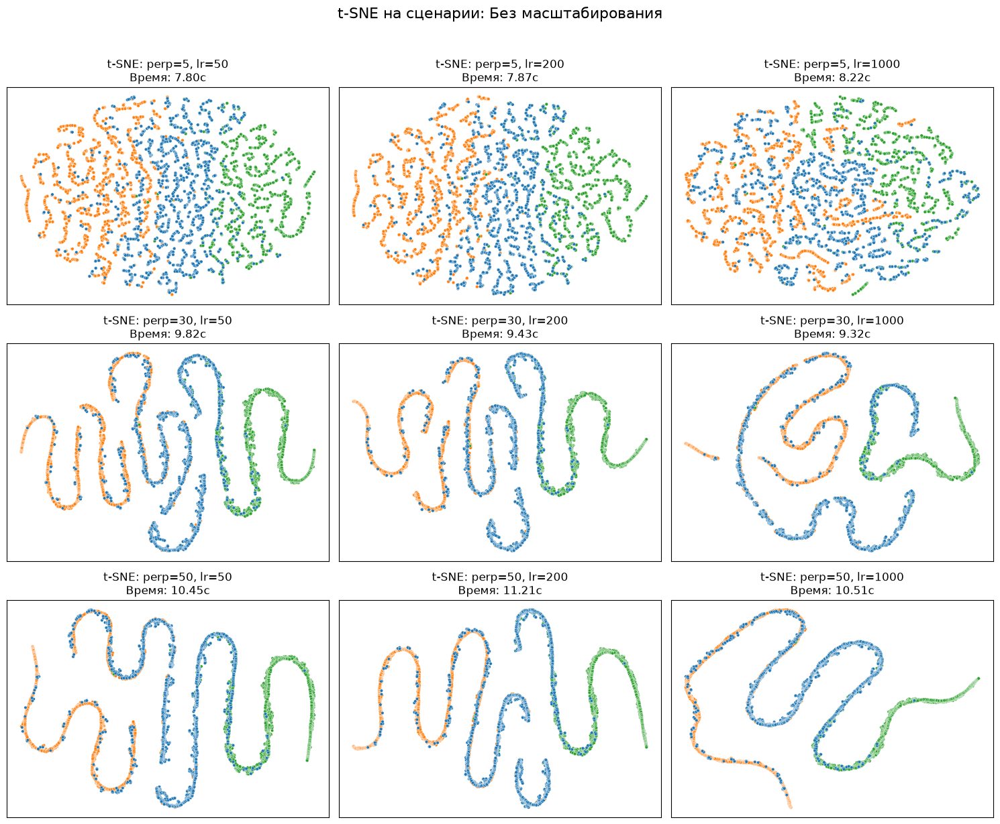


UMAP (Без масштабирования)


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may n

  n=5, md=0.0: 5.86с


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may n

  n=5, md=0.1: 6.23с


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may n

... (9 outputs left out)

c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=50, md=0.1: 11.71с


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=50, md=0.5: 11.16с


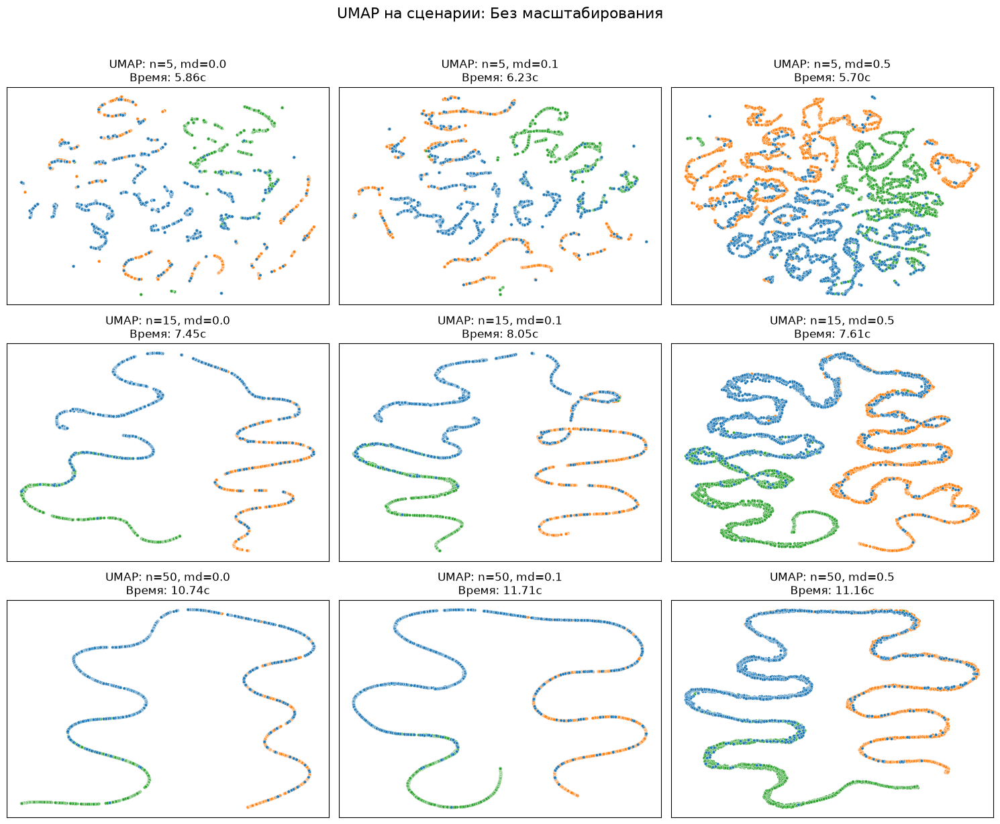

In [46]:
calc("Без масштабирования", X_raw)

Сценарий: StandardScaler

t-SNE (StandardScaler)
  perp=5, lr=50: 7.73с
  perp=5, lr=200: 8.05с
  perp=5, lr=1000: 9.18с
  perp=30, lr=50: 10.54с
  perp=30, lr=200: 10.95с
  perp=30, lr=1000: 11.55с
  perp=50, lr=50: 12.37с
  perp=50, lr=200: 12.44с
  perp=50, lr=1000: 12.70с


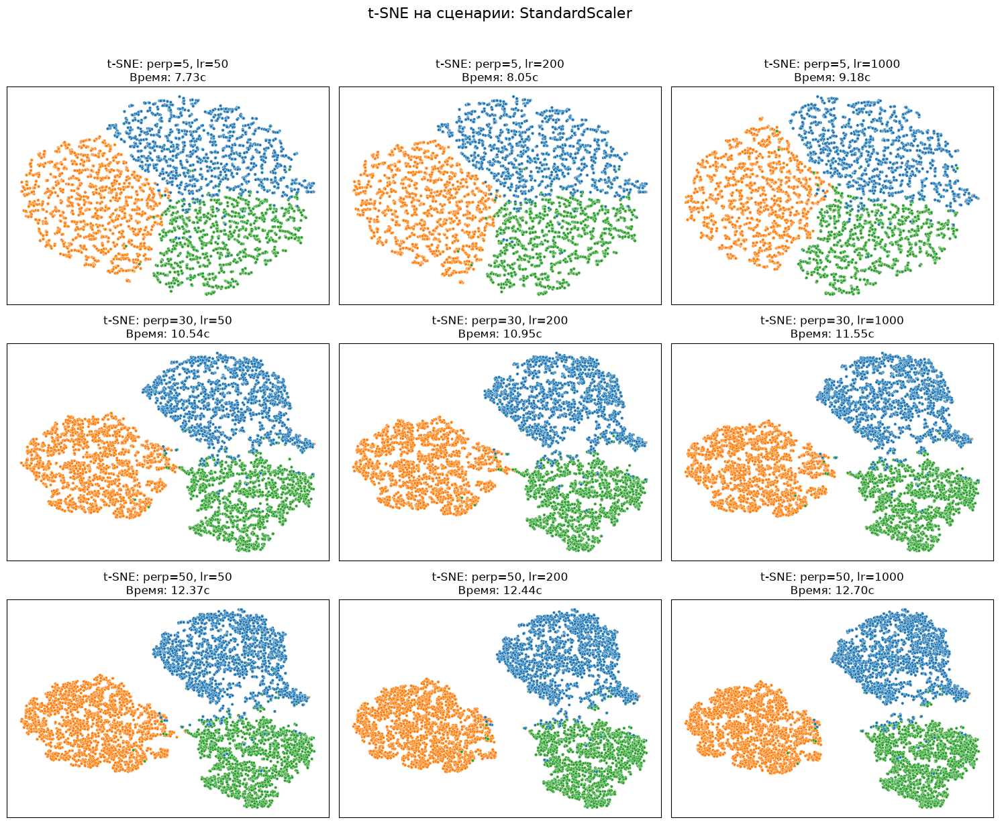


UMAP (StandardScaler)


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=5, md=0.0: 3.24с


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=5, md=0.1: 3.48с


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


... (9 outputs left out)

c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=50, md=0.1: 8.74с


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=50, md=0.5: 8.97с


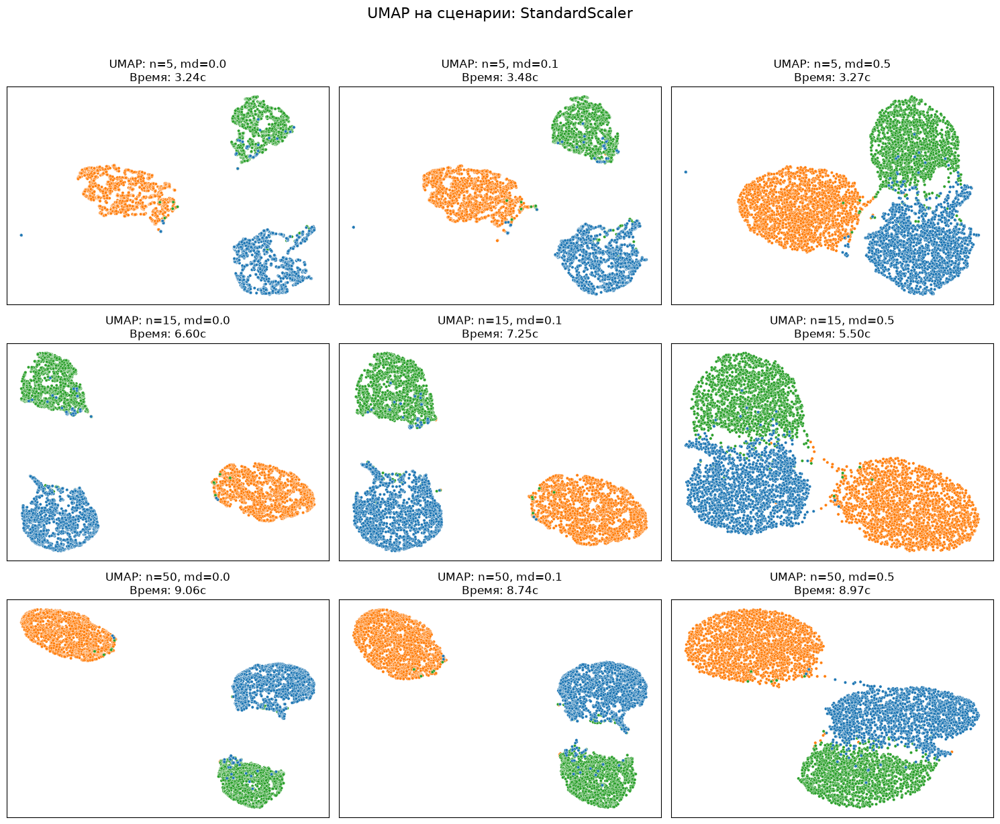

In [47]:
calc("StandardScaler", X_standard)

Сценарий: MinMax + отбор

t-SNE (MinMax + отбор)
  perp=5, lr=50: 8.63с
  perp=5, lr=200: 8.97с
  perp=5, lr=1000: 9.26с
  perp=30, lr=50: 10.66с
  perp=30, lr=200: 10.69с
  perp=30, lr=1000: 10.99с
  perp=50, lr=50: 12.51с
  perp=50, lr=200: 12.86с
  perp=50, lr=1000: 13.11с


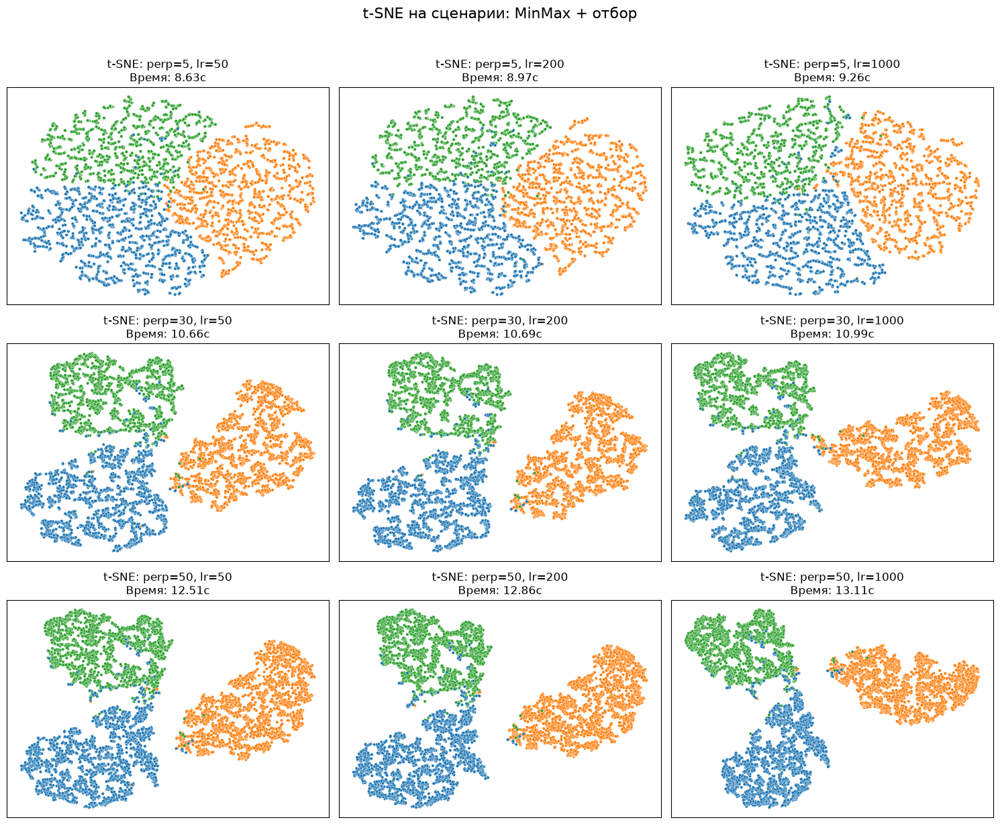


UMAP (MinMax + отбор)


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=5, md=0.0: 3.72с


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=5, md=0.1: 3.14с


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


... (9 outputs left out)

c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=50, md=0.1: 8.86с


c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Sofya\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=50, md=0.5: 7.98с


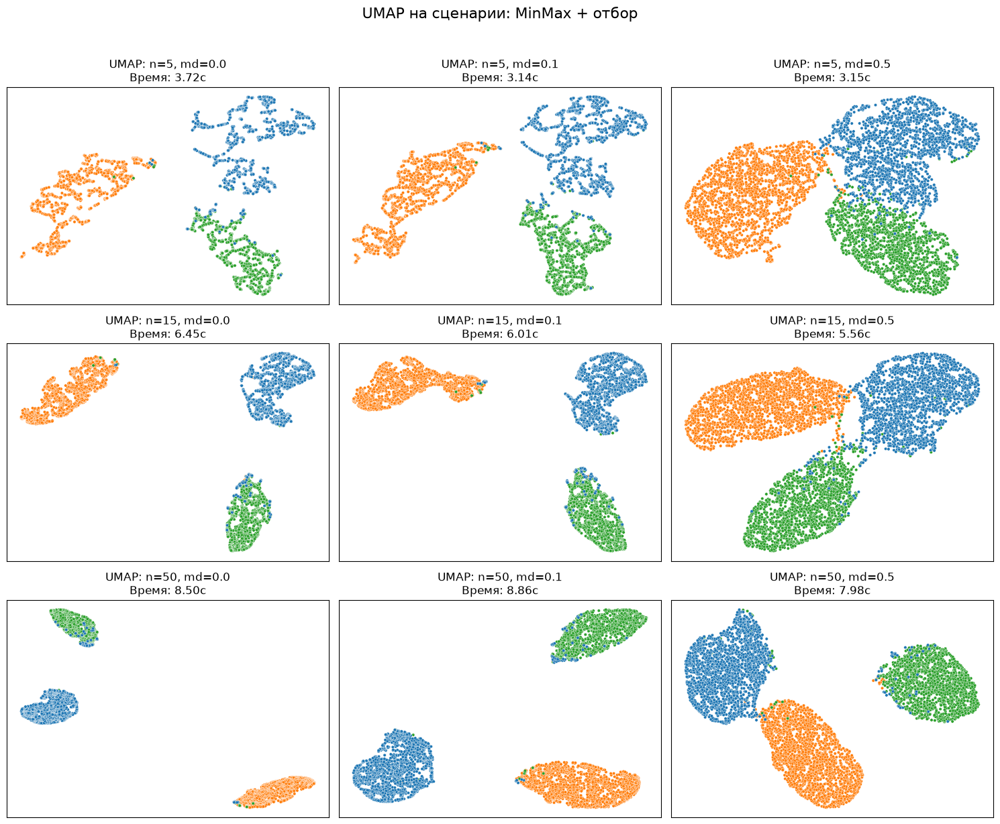

In [48]:
calc("MinMax + отбор", X_minmax_selected)

1. После MinMax-нормировки и отбора по дисперсии (порог 0.03) было отброшено 5 признаков: MinorAxisLength, Solidity, roundness, ShapeFactor1, ShapeFactor4. Это убирает шум, но лишает информации о некоторых геометрических различиях (например, выпуклости, округлости и малой оси боба). 
2. UMAP работает быстрее t-SNE во всех сценариях (особенно на нормированных данных). Нормировка (StandardScaler) и отбор признаков (MinMax) сокращают время работы UMAP с 5-12 до 3-9 секунд. t-SNE менее чувствителен к препроцессингу по времени (около 8-12 секунд во всех случаях). UMAP является более масштабируемым методом. 
3. Без масштабирования алгоритмы не справляются: формируются линии, узоры. Изменение гиперпараметров не спасает ситуацию. StandardScaler показывает хорошие результаты, при оптимальном подборе параметров удается получить плотные и разделенные кластеры (UMAP справляется лучше t-SNE). После MinMax-нормировки и отбора по дисперсии t-SNE чувствителен к изменениям обоих параметров, кластеры стали более рыхлыми, чем были после StandardScaler. UMAP менее чувствителен к изменению гиперпараметров, чем t-SNE. Кластеры плотные и хорошо разделены при определенном подборе параметров. Препроцессинг обязателен, без нормировки даже изменение гиперпараметров не дают результата. StandardScaler обеспечивает наилучшее качество структуры, сохраняя всю информацию о признаках.